# 02 — SST: เปลี่ยนคลื่น 1 มิติให้เป็นภาพเวลา–ความถี่

Synchrosqueezed Transform (SST) ช่วยให้โมเดลเห็นว่า “พลังงานความถี่ใดเกิดขึ้นเมื่อไร” ภายใน epoch 30 วินาที

เซลล์ในบทนี้ **อ่าน tensor ที่สร้างจริงจาก cache** ไม่ได้วาดภาพจำลอง และเปิดไฟล์ด้วย memory-map เพื่อไม่ดึง cache ขนาดประมาณ 249 GiB เข้า RAM

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "paper_faithful").is_dir())
sys.path.insert(0, str(ROOT / "walkthrough"))

import matplotlib.pyplot as plt
import numpy as np
from walkthrough_lib import *

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print(f"Project root : {PROJECT_ROOT}")
print(f"Bulk artifacts: {BULK_ROOT}")

Project root : C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction
Bulk artifacts: E:\blp\sleep_stage_reproduction


## 1. ขนาดของ cache และ route ที่ใช้

Stage 1–2 ใช้ `PAPER_PRETRAIN_V1` (12 windows) ส่วน Stage 3 ใช้ `PAPER_STAGE3_V1` (15 windows)

In [2]:
cache_manifest = load_json(CACHE_ROOT / "sst_full_cohort_run_manifest.json")
print("Full epochs represented:", f"{cache_manifest['capacity']['epochs']:,}")
print("Declared cache size:", f"{cache_manifest['capacity']['total_gib']:.3f} GiB")
print("Chunk size:", cache_manifest["chunk_epochs"], "epochs")
print("Routes:")
for route, size in cache_manifest["capacity"]["routes"].items():
    print(f"  {route:20s} {pretty_bytes(size)}")

Full epochs represented: 194,655
Declared cache size: 249.497 GiB
Chunk size: 32 epochs
Routes:
  AUTHOR_CODE_V1       89.11 GiB
  PAPER_PRETRAIN_V1    71.28 GiB
  PAPER_STAGE3_V1      89.11 GiB


## 2. เปิดตัวอย่างจริงหนึ่ง epoch

ค่าช่องสุดท้ายมี 2 channel คือ real และ imaginary component หลัง normalization

In [3]:
pretrain, pre_meta, pre_path = load_sst_example("PAPER_PRETRAIN_V1")
stage3, stage3_meta, stage3_path = load_sst_example("PAPER_STAGE3_V1")

print("Pretraining sample:", pretrain.shape, pretrain.dtype, "from", pre_path.name)
print("Stage-3 sample     :", stage3.shape, stage3.dtype, "from", stage3_path.name)
print("Only these two single-epoch arrays were copied to RAM.")

Pretraining sample: (12, 64, 64, 2) float32 from SC4001.PAPER_PRETRAIN_V1.00000000-00000032.npy
Stage-3 sample     : (15, 64, 64, 2) float32 from SC4001.PAPER_STAGE3_V1.00000000-00000032.npy
Only these two single-epoch arrays were copied to RAM.


## 3. ดูภาพ SST จริง

ภาพแต่ละแถวคือ window ต้น กลาง และท้ายของ epoch เดียวกัน คอลัมน์แสดง real, imaginary และ magnitude

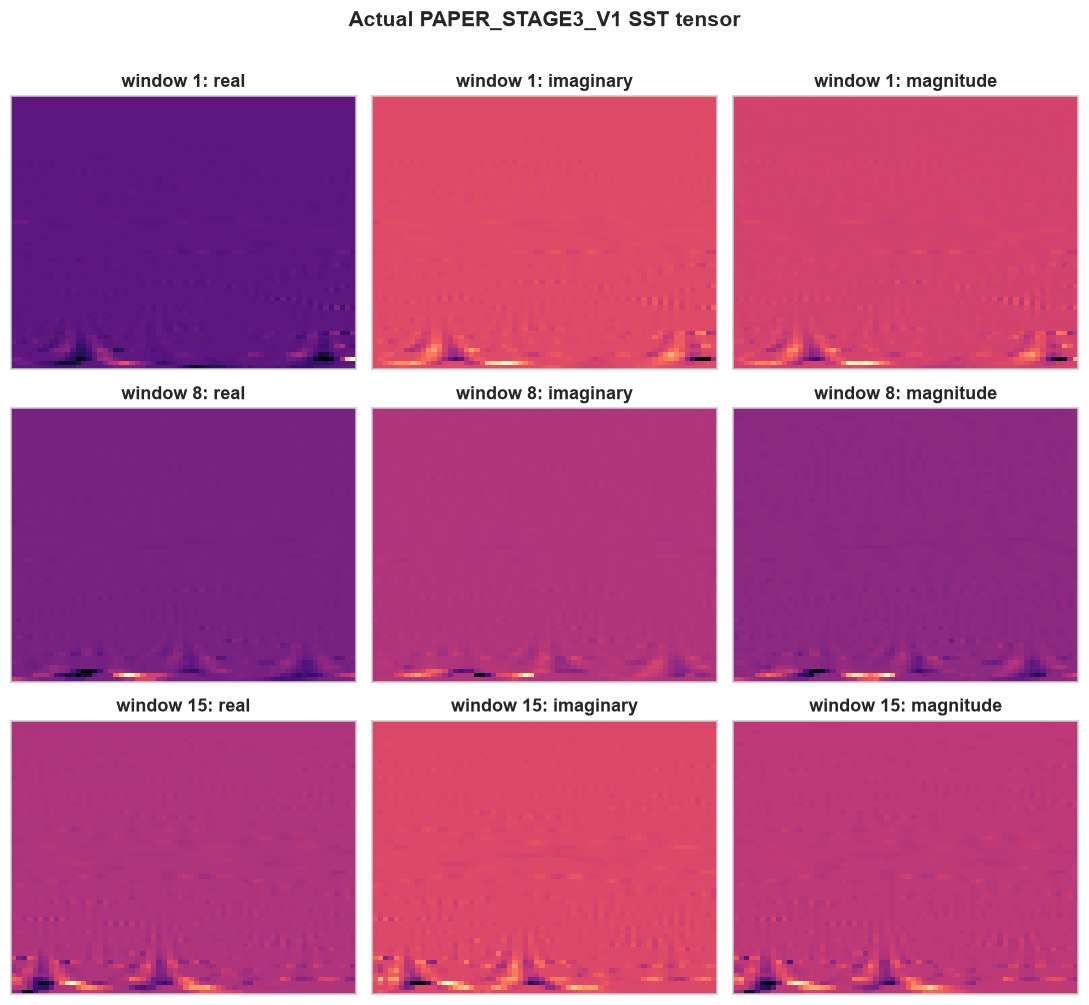

In [4]:
indices = [0, stage3.shape[0] // 2, stage3.shape[0] - 1]
fig, axes = plt.subplots(3, 3, figsize=(10, 9))
for row, index in enumerate(indices):
    real = stage3[index, :, :, 0]
    imag = stage3[index, :, :, 1]
    magnitude = np.sqrt(real**2 + imag**2)
    for col, (image, name) in enumerate(((real, "real"), (imag, "imaginary"), (magnitude, "magnitude"))):
        axes[row, col].imshow(image, origin="lower", aspect="auto", cmap="magma")
        axes[row, col].set_title(f"window {index + 1}: {name}")
        axes[row, col].set(xticks=[], yticks=[])
fig.suptitle("Actual PAPER_STAGE3_V1 SST tensor", y=1.01, fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

## 4. ทำไมมี 12 กับ 15 windows

- บทความกำหนด 12 windows สำหรับการเรียนรู้ representation ใน Stage 1–2
- Stage 3 ใช้ sequence 15 windows เพื่อให้ GRU มองความต่อเนื่องตามเวลา
- ค่า overlap ของ Stage 3 ไม่ได้ระบุชัดในข้อความบทความ จึงใช้ 64 ตามโค้ดผู้เขียนและบันทึกว่าเป็น **inference** ไม่ใช่ข้อเท็จจริงจากข้อความ paper

route             | windows | width | overlap | provenance                       
------------------+---------+-------+---------+----------------------------------
PAPER_PRETRAIN_V1 | 12      | 256   | 7       | manuscript text                  
PAPER_STAGE3_V1   | 15      | 256   | 64      | overlap inferred from author code


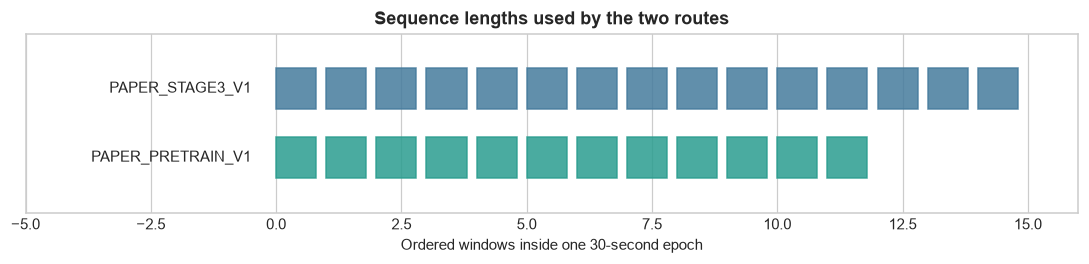

In [5]:
protocol = paper_protocol()
model = protocol["model"]
rows = [
    {"route": "PAPER_PRETRAIN_V1", "windows": model["pretraining_windows"], "width": model["width"], "overlap": model["overlap"], "provenance": "manuscript text"},
    {"route": "PAPER_STAGE3_V1", "windows": model["stage3_windows"], "width": model["width"], "overlap": model["stage3_overlap"], "provenance": "overlap inferred from author code"},
]
print_records(rows, ["route", "windows", "width", "overlap", "provenance"])

fig, ax = plt.subplots(figsize=(10, 2.5))
for i, row in enumerate(rows):
    count = row["windows"]
    for j in range(count):
        ax.add_patch(plt.Rectangle((j, i - 0.3), 0.8, 0.6, color="#2a9d8f" if i == 0 else "#457b9d", alpha=0.85))
    ax.text(-0.5, i, row["route"], ha="right", va="center")
ax.set_xlim(-5, 16)
ax.set_ylim(-0.8, 1.8)
ax.set_yticks([])
ax.set_xlabel("Ordered windows inside one 30-second epoch")
ax.set_title("Sequence lengths used by the two routes")
plt.tight_layout()
plt.show()

**สรุป:** เรามีทั้งข้อมูลเต็มที่ preprocess แล้วและ SST cache เต็มพร้อม hash/provenance การเปิดดูตัวอย่างนี้ไม่ใช่หลักฐานว่าโมเดลให้ผลดี แต่เป็นหลักฐานว่าท่อข้อมูลถึงจุดป้อนโมเดลทำงานและตรวจย้อนกลับได้